# Real-Time Drowsiness Detection (Colab Version)

Detects drowsiness in a video using **MediaPipe Face Mesh** and the **Eye Aspect Ratio (EAR)**.

**How to use:** record a 10-30 second video of your face (phone or laptop, good lighting, face toward the camera), blink normally, then close your eyes for 1-2 seconds a couple of times. Run the cells in order and upload the video when asked.

> Re-implementation of my original 2024 drowsiness detection project.

## 1. Install libraries
Run this cell. If Colab shows a button asking you to **Restart session**, click it and continue from cell 2. If it does not, just continue.

In [8]:
!pip install -q mediapipe

## 2. Imports and helper functions

In [9]:
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
import matplotlib.pyplot as plt

# [p1 outer corner, p2, p3 upper lid, p4 inner corner, p5, p6 lower lid]
RIGHT_EYE = [33, 160, 158, 133, 153, 144]
LEFT_EYE = [362, 385, 387, 263, 373, 380]

def eye_aspect_ratio(pts):
    """EAR = (|p2-p6| + |p3-p5|) / (2 * |p1-p4|). Close to 0 when the eye is closed."""
    p1, p2, p3, p4, p5, p6 = pts
    return float((np.linalg.norm(p2 - p6) + np.linalg.norm(p3 - p5)) / (2.0 * np.linalg.norm(p1 - p4) + 1e-6))

def to_pixels(face, idx, w, h):
    # face is a list of normalized landmarks (x, y in 0-1)
    return np.array([(face[i].x * w, face[i].y * h) for i in idx])

print("OpenCV", cv2.__version__)

OpenCV 4.14.0


## 3. Download the face landmark model
This downloads Google's free MediaPipe Face Landmarker model (about 4 MB).

In [10]:
!wget -q -O face_landmarker.task https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task
!ls -lh face_landmarker.task

-rw-r--r-- 1 root root 3.6M May  3  2023 face_landmarker.task


## 4. Settings
- `EAR_THRESHOLD`: EAR below this means the eyes are closed. Typical range 0.18-0.25.
- `MIN_CLOSED_SECONDS`: how long the eyes must stay closed before an alert (a normal blink is under 0.4 s).
- `PRIVACY_MODE`: when `True`, the output video never shows your face, only the eye outlines, EAR value and alerts on a black background. Safe to share publicly.

In [11]:
EAR_THRESHOLD = 0.21
MIN_CLOSED_SECONDS = 1.0
PRIVACY_MODE = True   # True = hide the face: output shows only eye outlines on a black background

## 5. Upload your video

In [12]:
from google.colab import files
uploaded = files.upload()
video_path = list(uploaded.keys())[0]
print("Using:", video_path)

Saving WhatsApp Video 2026-10-20 at 9.36.47 PM.mp4 to WhatsApp Video 2026-10-20 at 9.36.47 PM.mp4
Using: WhatsApp Video 2026-10-20 at 9.36.47 PM.mp4


## 6. Run detection

In [13]:
def process_video(path, out_path="annotated_raw.mp4", ear_thr=EAR_THRESHOLD, min_seconds=MIN_CLOSED_SECONDS):
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    scale = 640 / max(int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), 1)
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH) * scale)
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT) * scale)
    writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
    options = vision.FaceLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path="face_landmarker.task"),
        running_mode=vision.RunningMode.VIDEO, num_faces=1)
    landmarker = vision.FaceLandmarker.create_from_options(options)
    need_frames = max(1, int(min_seconds * fps))
    closed, alerts, in_alert = 0, 0, False
    ears = []
    frame_idx = 0

    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frame = cv2.resize(frame, (w, h))
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb))
        res = landmarker.detect_for_video(mp_image, int(frame_idx * 1000 / fps))
        frame_idx += 1
        if PRIVACY_MODE:
            frame = np.zeros_like(frame)   # remove the face from the output
        ear = np.nan
        if res.face_landmarks:
            face = res.face_landmarks[0]
            right, left = to_pixels(face, RIGHT_EYE, w, h), to_pixels(face, LEFT_EYE, w, h)
            ear = (eye_aspect_ratio(right) + eye_aspect_ratio(left)) / 2
            for eye in (right, left):
                cv2.polylines(frame, [eye.astype(np.int32)], True, (0, 255, 0), 2)
            if ear < ear_thr:
                closed += 1
            else:
                closed, in_alert = 0, False
            if closed >= need_frames:
                if not in_alert:
                    alerts, in_alert = alerts + 1, True
                cv2.putText(frame, "DROWSINESS ALERT!", (20, 80), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (0, 0, 255), 3)
        else:
            closed = 0
            cv2.putText(frame, "No face detected", (20, 80), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 165, 255), 2)
        cv2.putText(frame, f"EAR: {ear:.2f}" if not np.isnan(ear) else "EAR: --", (20, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
        cv2.putText(frame, f"Alerts: {alerts}", (20, 55), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1)
        writer.write(frame)
        ears.append(ear)

    cap.release(); writer.release(); landmarker.close()
    return np.array(ears), fps, alerts

ears, fps, alerts = process_video(video_path)
print(f"Frames: {len(ears)} | FPS: {fps:.0f} | Drowsiness alerts: {alerts}")
print(f"Face found in {100 * np.mean(~np.isnan(ears)):.0f}% of frames")

Frames: 266 | FPS: 30 | Drowsiness alerts: 1
Face found in 100% of frames


## 7. Watch the result

In [14]:
!ffmpeg -y -loglevel error -i annotated_raw.mp4 -vcodec libx264 -pix_fmt yuv420p annotated.mp4
from IPython.display import HTML
from base64 import b64encode
data = b64encode(open("annotated.mp4", "rb").read()).decode()
HTML(f'<video width=640 controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>')

## 8. EAR over time

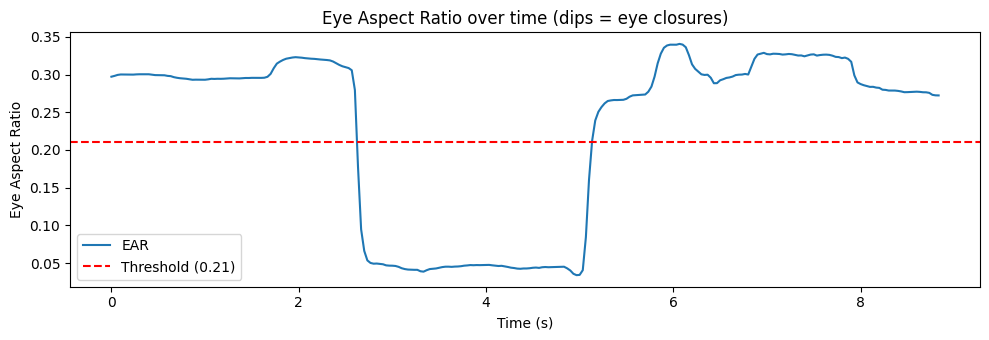

In [15]:
t = np.arange(len(ears)) / fps
plt.figure(figsize=(10, 3.5))
plt.plot(t, ears, label="EAR")
plt.axhline(EAR_THRESHOLD, color="red", linestyle="--", label=f"Threshold ({EAR_THRESHOLD})")
plt.xlabel("Time (s)"); plt.ylabel("Eye Aspect Ratio")
plt.title("Eye Aspect Ratio over time (dips = eye closures)")
plt.legend(); plt.tight_layout()
plt.savefig("ear_plot.png", dpi=150)
plt.show()

## 9. Download results
Download `annotated.mp4` and `ear_plot.png` from the Files panel (folder icon on the left) and add them to your GitHub README.

## How it works
1. MediaPipe Face Landmarker finds facial landmarks in every frame.
2. Six landmarks per eye give the Eye Aspect Ratio.
3. If EAR stays below the threshold for the set time, an alert is raised.

## Limitations
The threshold varies between people, and detection gets worse in low light, with glare on glasses, or when the face is turned away.